# Chapter 3 — Classification: MNIST Handwritten Digits
## Week 1 Day 2: Setup, Data Loading & Exploration

In this chapter, we transition from regression (predicting continuous house prices) to **classification** (predicting discrete categorical classes).

### The Problem: MNIST Digit Recognition
The MNIST dataset is the famous "Hello World" of Machine Learning:
- **70,000 small grayscale images** of handwritten digits (0 through 9) collected from US Census Bureau employees and high school students.
- Each image is **28 × 28 pixels** ($= 784$ total features per image).
- Each pixel has an intensity value ranging from `0` (white background) to `255` (black ink).

---

## 1. Setup & Starter Imports

We configure our visualization settings, random seeds, and starter imports from NumPy, Pandas, Matplotlib, and Scikit-Learn:

💡 **Python Syntax & Setup Explained:**
- `%matplotlib inline`: Ensures plots render directly within this notebook.
- `np.random.seed(42)`: Freezes the random number generator so stochastic algorithms (like SGD) produce deterministic results.
- Core classification imports included for Chapter 3:
  - `SGDClassifier`: Linear classifier using Stochastic Gradient Descent (efficient for large datasets like 60k images).
  - `cross_val_score` & `cross_val_predict`: Cross-validation tools to evaluate models without touching the test set.
  - `confusion_matrix`, `precision_score`, `recall_score`, `f1_score`, `roc_auc_score`: The essential classification performance metrics.

In [1]:
# Common imports
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Scikit-Learn tools & models for Chapter 3
from sklearn.utils import Bunch
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    roc_curve,
    roc_auc_score,
)

# Matplotlib plotting configuration
%matplotlib inline
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)
np.random.seed(42)

print("Setup completed successfully!")

Setup completed successfully!


--- 
## 2. Load the MNIST Dataset

### ⚠️ The OpenML Network Issue & Our Robust Solution
In Scikit-Learn, the standard command is `fetch_openml('mnist_784', version=1)`. However, the OpenML servers frequently experience connection timeouts, network throttling, or downtime.

To make this notebook **100% resilient and offline-ready**, the function below:
1. Checks for a local cached file `../data/mnist.npz` (downloaded once from a high-speed mirror).
2. Reshapes the 28x28 arrays into flat 784-dimensional vectors matching `fetch_openml`.
3. Wraps the arrays in an official Scikit-Learn `Bunch` dictionary object so that `mnist.keys()`, `mnist["data"]`, and `mnist["target"]` behave identically to `fetch_openml`.

In [2]:
def load_mnist():
    """
    Reliably loads MNIST dataset into a Scikit-Learn Bunch object.
    Uses a local cache at ../data/mnist.npz (or auto-downloads from Google Storage mirror)
    to avoid openml.org connection timeouts.
    """
    data_dir = os.path.join("..", "data")
    os.makedirs(data_dir, exist_ok=True)
    mnist_path = os.path.join(data_dir, "mnist.npz")
    
    if not os.path.exists(mnist_path):
        print("Local cache not found. Downloading mnist.npz from mirror (~11.5 MB)...", end=" ")
        url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
        urllib.request.urlretrieve(url, mnist_path)
        print("Done!")
    
    with np.load(mnist_path) as npz:
        x_train, y_train = npz["x_train"], npz["y_train"]
        x_test, y_test = npz["x_test"], npz["y_test"]
    
    # Concatenate 60k train + 10k test into full 70k dataset (70000, 784)
    X = np.concatenate([x_train.reshape(-1, 784), x_test.reshape(-1, 784)], axis=0)
    # OpenML stores targets as strings ('0' to '9')
    y = np.concatenate([y_train.astype(str), y_test.astype(str)], axis=0)
    
    return Bunch(
        data=X,
        target=y,
        frame=None,
        categories={},
        feature_names=[f"pixel{i}" for i in range(784)],
        target_names=["class"],
        DESCR="MNIST handwritten digits dataset",
        details={},
        url="https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
    )

# Load the dataset and inspect dictionary keys
mnist = load_mnist()
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

--- 
## 3. Inspecting Dataset Structure

Let's extract the feature matrix `X` and target labels `y` and inspect their dimensions:

💡 **Python Syntax Explained:**
- `X, y = mnist["data"], mnist["target"]`: Extracts the features and labels using standard dictionary indexing.
- `X.shape`: Returns `(70000, 784)` $\rightarrow$ 70,000 images, each having 784 pixel values.
- `y.shape`: Returns `(70000,)` $\rightarrow$ 70,000 ground truth digit labels.

In [3]:
X, y = mnist["data"], mnist["target"]

print("Feature matrix X shape:", X.shape)
print("Target labels y shape:  ", y.shape)

Feature matrix X shape: (70000, 784)
Target labels y shape:   (70000,)


--- 
## 4. Visualizing a Handwritten Digit

To see what a handwritten digit looks like, we grab a single feature vector of length 784, reshape it into a $28 \times 28$ matrix, and plot it with `imshow()`:

💡 **Python Syntax Explained:**
- `image_data.reshape(28, 28)`: Reshapes a 1D array of 784 pixels into a 2D $28 \times 28$ grid.
- `plt.imshow(image, cmap="binary")`: Renders the array as an image. `cmap="binary"` displays `0` as white and `255` as black.
- `plt.axis("off")`: Hides the axis coordinate numbers for a clean look.

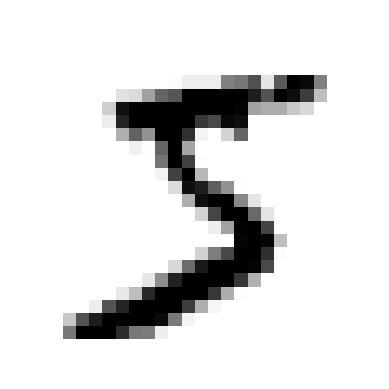

Corresponding ground truth label: 5
Data type of labels: <class 'numpy.str_'>


In [4]:
def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

some_digit = X[0]
plot_digit(some_digit)
plt.show()

print("Corresponding ground truth label:", y[0])
print("Data type of labels:", type(y[0]))

--- 
## 5. Preparing the Train / Test Split

Notice above that `y[0]` is a string `'5'`, not a number. Most ML algorithms expect numerical values, so we convert `y` to integers with `.astype(np.uint8)`.

The MNIST dataset is already pre-split:
- The **first 60,000 images** form the training set.
- The **last 10,000 images** form the test set.

💡 **Python Syntax Explained:**
- `y = y.astype(np.uint8)`: Casts the string labels (`'0'` through `'9'`) into unsigned 8-bit integers (`0` through `9`).
- `X[:60000]`: Python slice taking the first 60,000 samples for training.
- `X[60000:]`: Python slice taking the remaining 10,000 samples for testing.

In [5]:
# Cast labels from string to integers
y = y.astype(np.uint8)

# Split into 60,000 training images and 10,000 test images
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape},  y_test shape:  {y_test.shape}")
print("\nReady for Chapter 3 classification tasks! (Next step: Training a binary '5-Detector')")

X_train shape: (60000, 784), y_train shape: (60000,)
X_test shape:  (10000, 784),  y_test shape:  (10000,)

Ready for Chapter 3 classification tasks! (Next step: Training a binary '5-Detector')
